El modelo AR(p) (Autoregressive Model of Order p, o Modelo Autorregresivo de orden p) es la generalización del AR(1): el valor actual de una variable depende linealmente de sus **p** valores inmediatamente anteriores más un término aleatorio. El AR(1) es el caso particular $p=1$.

### Definición matemática

Un proceso AR(p) se expresa como:

$$X_t = \phi_1 X_{t-1} + \phi_2 X_{t-2} + \cdots + \phi_p X_{t-p} + \varepsilon_t$$

o, en forma compacta:

$$X_t = \sum_{i=1}^{p} \phi_i X_{t-i} + \varepsilon_t$$

donde:
- $X_t$: valor de la serie en el instante $t$.
- $X_{t-i}$: valor de la serie $i$ instantes antes.
- $\phi_i$: $i$-ésimo coeficiente autorregresivo.
- $p$: orden del modelo (número de rezagos).
- $\varepsilon_t$: ruido blanco con media cero y varianza constante $\sigma^2$.

Cuando la serie tiene una media distinta de cero, suele escribirse como:

$$X_t = c + \sum_{i=1}^{p} \phi_i X_{t-i} + \varepsilon_t$$

donde $c$ es una constante. El modelo tiene $p+1$ parámetros de regresión ($c,\phi_1,\dots,\phi_p$) más la varianza $\sigma^2$ del ruido.

### Interpretación física

El modelo AR(p) establece que el estado presente conserva una "memoria" de los $p$ instantes anteriores, es decir, de una ventana de duración $p\,\Delta t$, donde $\Delta t$ es el periodo de muestreo.

Por ejemplo:
- Temperatura ambiental actual.
- Humedad relativa actual.
- Concentración de PM2.5.
- Velocidad del viento.

Con $p=1$ el modelo solo "ve" el último dato. Con $p\geq 2$ puede comparar rezagos entre sí y, por tanto, capturar **tendencia e inercia**. Por ejemplo, el AR(2) con $\phi_1=2$, $\phi_2=-1$ equivale a:

$$X_t = X_{t-1} + (X_{t-1}-X_{t-2})$$

es decir, el valor actual es el anterior más el último cambio observado. Si la temperatura viene subiendo 0.3 °C por minuto, un AR(2) puede reconocer esa pendiente; un AR(1) no.

### Propiedad de estacionariedad

Se define el **polinomio característico** del proceso:

$$\Phi(z)=1-\phi_1 z-\phi_2 z^2-\cdots-\phi_p z^p$$

Un proceso AR(p) es estacionario si **todas las raíces de $\Phi(z)=0$ están fuera del círculo unitario** ($|z|>1$). De forma equivalente, todas las raíces $\lambda$ de

$$\lambda^p-\phi_1\lambda^{p-1}-\cdots-\phi_{p-1}\lambda-\phi_p=0$$

deben cumplir $|\lambda|<1$ (con $\lambda=1/z$). Esta es la condición que se verifica numéricamente en el código.

Para $p=1$ la condición se reduce a $|\phi|<1$.

Condiciones útiles:
- **Necesaria (cualquier $p$):** $\sum_{i=1}^{p}\phi_i<1$.
- **AR(2):** $\phi_1+\phi_2<1$, $\;\phi_2-\phi_1<1$ y $|\phi_2|<1$.

Esto significa que la influencia de los valores pasados disminuye conforme transcurre el tiempo.

**Caso 1:** todas las raíces $\lambda$ son reales con $|\lambda|<1$.

Existe persistencia con decaimiento exponencial, como en el AR(1) con $\phi>0$.

Ejemplo:

$$\phi_1=0.5,\quad \phi_2=0.3 \qquad (\textstyle\sum\phi_i=0.8,\ \lambda=0.852,\,-0.352)$$

Si la serie aumenta en un instante, tenderá a permanecer elevada durante varios periodos.

**Caso 2:** raíces complejas conjugadas con $|\lambda|<1$.

Aparecen **oscilaciones amortiguadas** (comportamiento pseudo-periódico), algo que el AR(1) no puede reproducir. En el AR(2) ocurre cuando $\phi_1^2+4\phi_2<0$.

Ejemplo:

$$\phi_1=1,\quad \phi_2=-0.5 \qquad (\lambda=0.5\pm0.5i,\ |\lambda|=0.707)$$

La serie sube, baja y se va atenuando:
- valor alto
- valor intermedio
- valor bajo
- valor intermedio, con amplitud cada vez menor

**Caso 3:** raíz unitaria, $\sum_{i=1}^{p}\phi_i=1$.

Existe una raíz $\lambda=1$. Es la generalización del paseo aleatorio del AR(1):

$$X_t = X_{t-1} + \varepsilon_t$$

Ejemplo: $\phi_1=0.7,\ \phi_2=0.3$ ($\lambda=1,\,-0.3$).

La serie deja de ser estacionaria y suele tratarse diferenciándola (modelos ARIMA).

**Caso 4:** alguna raíz con $|\lambda|>1$.

El proceso es explosivo.

Ejemplo: $\phi_1=0.8,\ \phi_2=0.5$ ($\sum\phi_i=1.3$, $\lambda=1.212,\,-0.412$).

Pequeñas perturbaciones crecen indefinidamente.

> **Nota práctica.** En variables físicas muy suaves y muestreadas con frecuencia alta (por ejemplo temperatura cada minuto) es común que el ajuste dé $\sum\phi_i\approx 1$, es decir, un modelo en la frontera de la estacionariedad. Por eso conviene revisar siempre el módulo máximo de las raíces, no solo cada $\phi_i$.

### Media del proceso

Para el modelo

$$X_t=c+\sum_{i=1}^{p}\phi_i X_{t-i}+\varepsilon_t$$

tomando esperanzas con $E[X_t]=\mu$ constante, la media estacionaria es:

$$\mu=\frac{c}{1-\phi_1-\phi_2-\cdots-\phi_p}=\frac{c}{1-\sum_{i=1}^{p}\phi_i}$$

(definida solo si $\sum\phi_i\neq 1$). Para $p=1$ se recupera $\mu=c/(1-\phi)$.

### Varianza del proceso

La varianza estacionaria es:

$$\gamma_0=Var(X_t)=\frac{\sigma_\varepsilon^2}{1-\sum_{i=1}^{p}\phi_i\,\rho(i)}$$

donde:
- $\sigma_\varepsilon^2$ es la varianza del ruido blanco.
- $\rho(i)$ es la autocorrelación en el retardo $i$.

Para $p=1$, como $\rho(1)=\phi$, se recupera $Var(X_t)=\sigma_\varepsilon^2/(1-\phi^2)$.

Puede observarse que conforme $\sum\phi_i\rho(i)$ se acerca a 1, la varianza aumenta considerablemente.

### Funciones de autocorrelación (ACF) y autocorrelación parcial (PACF)

En el AR(p) la autocorrelación ya no es simplemente $\phi^k$. Satisface la **recursión de Yule–Walker**:

$$\rho(k)=\phi_1\rho(k-1)+\phi_2\rho(k-2)+\cdots+\phi_p\rho(k-p),\qquad k\geq 1$$

con $\rho(0)=1$ y $\rho(-k)=\rho(k)$. La ACF decae como una combinación de exponenciales y/o senoides amortiguadas. Para $p=1$ se recupera $\rho(k)=\phi^k$.

Por ejemplo, para el AR(2) con:

$$\phi_1=0.6,\quad \phi_2=0.3$$

se tiene $\rho(1)=\dfrac{\phi_1}{1-\phi_2}=0.857$ y el resto sale de la recursión:

| Retardo | Autocorrelación |
| :---: | :---: |
| 1 | 0.857 |
| 2 | 0.814 |
| 3 | 0.746 |
| 4 | 0.692 |

La memoria del sistema disminuye gradualmente.

**PACF.** La autocorrelación parcial en el retardo $k$, $\phi_{kk}$, es el último coeficiente de un ajuste AR($k$). Para un proceso AR(p), la PACF es **cero para $k>p$** (se "corta" en $p$), mientras que la ACF decae gradualmente. Por eso la PACF es la herramienta principal para identificar el orden $p$. Con $N$ datos, las bandas aproximadas de no significancia son $\pm 1.96/\sqrt{N}$.

### Representación mediante operador de retardo

Definiendo el operador:

$$B^iX_t=X_{t-i}$$

el modelo puede escribirse como:

$$(1-\phi_1 B-\phi_2 B^2-\cdots-\phi_p B^p)X_t=\varepsilon_t \quad\Longleftrightarrow\quad \Phi(B)X_t=\varepsilon_t$$

y, con constante, $\Phi(B)X_t=c+\varepsilon_t$. Observe que $\Phi(B)$ es el mismo polinomio característico de la sección de estacionariedad, evaluado en $B$.

Esta representación es muy útil para desarrollar la teoría de los modelos ARIMA.

### Ecuaciones de Yule–Walker

Multiplicando el modelo (sin constante, serie centrada) por $X_{t-k}$ y tomando esperanzas para $k=1,\dots,p$, se obtiene el sistema:

$$\begin{bmatrix}1&\rho_1&\cdots&\rho_{p-1}\\ \rho_1&1&\cdots&\rho_{p-2}\\ \vdots&\vdots&\ddots&\vdots\\ \rho_{p-1}&\rho_{p-2}&\cdots&1\end{bmatrix}\begin{bmatrix}\phi_1\\ \phi_2\\ \vdots\\ \phi_p\end{bmatrix}=\begin{bmatrix}\rho_1\\ \rho_2\\ \vdots\\ \rho_p\end{bmatrix}
\qquad\Longleftrightarrow\qquad \mathbf{R}\,\boldsymbol{\phi}=\mathbf{r}$$

de donde $\boldsymbol{\phi}=\mathbf{R}^{-1}\mathbf{r}$ y $\sigma^2=\gamma_0\left(1-\sum_i\phi_i\rho_i\right)$.

Sustituyendo las autocorrelaciones muestrales se obtiene un estimador alternativo al de mínimos cuadrados. Para $p=1$, $\mathbf{R}=[1]$ y $\phi=\rho_1$.

En este cuaderno se estima por **mínimos cuadrados ordinarios (MCO)**; Yule–Walker queda como base teórica de la ACF/PACF.

### Predicción con AR(p)

Si se conocen los últimos $p$ valores $X_t,X_{t-1},\dots,X_{t-p+1}$, la predicción a un paso adelante es:

$$\hat X_{t+1}=c+\phi_1 X_t+\phi_2 X_{t-1}+\cdots+\phi_p X_{t-p+1}$$

Para horizontes mayores la predicción es **recursiva**: los valores aún no observados se sustituyen por sus propias predicciones:

$$\hat X_{t+h}=c+\sum_{i=1}^{p}\phi_i\,\hat X_{t+h-i},\qquad \hat X_{t+j}=X_{t+j}\ \text{ si } j\leq 0$$

Para $p=1$ y $c=0$ se recupera $\hat X_{t+h}=\phi^h X_t$.

A medida que aumenta el horizonte $h$, la predicción converge hacia la media del proceso $\mu$ (si es estacionario).

**Incertidumbre.** El error de predicción a $h$ pasos tiene varianza $\sigma^2\sum_{j=0}^{h-1}\psi_j^2$, donde $\psi_0=1$ y $\psi_j=\sum_{i=1}^{\min(j,p)}\phi_i\psi_{j-i}$. Un intervalo aproximado al 95 % es $\hat X_{t+h}\pm1.96\,\sigma\sqrt{\sum_{j=0}^{h-1}\psi_j^2}$.

### Ejemplo numérico

Suponga el modelo AR(2):

$$X_t=0.5X_{t-1}+0.3X_{t-2}+\varepsilon_t$$

y que:

$$X_9=18,\qquad X_{10}=20$$

Entonces:

**Predicción a un paso:**

$$\hat X_{11}=0.5(20)+0.3(18)=15.4$$

**Predicción a dos pasos:**

$$\hat X_{12}=0.5(15.4)+0.3(20)=13.7$$

**Predicción a tres pasos:**

$$\hat X_{13}=0.5(13.7)+0.3(15.4)=11.47$$

Como $\sum\phi_i=0.8<1$, el modelo es estacionario con $\mu=0$ y la influencia de los datos iniciales disminuye progresivamente.

### Selección del orden $p$

El orden no es conocido de antemano. Se combinan tres criterios:

1. **PACF:** el último retardo significativo (fuera de $\pm1.96/\sqrt N$) sugiere $p$.
2. **Criterios de información:** con $n$ pares, $k=p+1$ parámetros y $\hat\sigma^2_{MV}=SSE/n$,

$$AIC=n\ln(\hat\sigma^2_{MV})+2k \qquad\qquad BIC=n\ln(\hat\sigma^2_{MV})+k\ln n$$

   Se elige el $p$ que minimiza el criterio. El BIC penaliza más la complejidad y tiende a elegir modelos más parsimoniosos. Para que sean comparables, todos los órdenes se ajustan sobre **la misma muestra** (se descartan los primeros $p_{max}$ datos).
3. **Diagnóstico de residuales:** si el orden es suficiente, los residuales se comportan como ruido blanco (su ACF queda dentro de las bandas).

Por parsimonia, entre dos órdenes con desempeño similar se prefiere el menor.

### Usos y extensiones

El AR(p) suele emplearse para:
- Predicción de temperatura en invernaderos.
- Predicción de humedad relativa.
- Modelado de déficit de presión de vapor (DPV).
- Predicción de velocidad del viento.
- Predicción de concentración de contaminantes (PM2.5 y PM10).
- Modelado de radiación solar.

Sin embargo, para variables con componente de media móvil, tendencia, estacionalidad (por ejemplo, el ciclo diario de temperatura) o comportamientos no lineales suele extenderse a modelos:
- ARMA
- ARIMA
- SARIMA
- VAR
- Redes neuronales recurrentes (LSTM, GRU)
- Modelos híbridos Grey–Deep Learning

que capturan dependencias de mayor longitud y patrones no lineales.

### Resumen

El modelo AR(p) supone que el valor actual de una serie temporal depende de sus $p$ valores inmediatamente anteriores y de una perturbación aleatoria. Generaliza al AR(1) (que es el caso $p=1$), permite representar inercia y oscilaciones, y constituye la base teórica de gran parte del análisis moderno de series de tiempo, identificación de sistemas y predicción de variables ambientales.

## Estimación por mínimos cuadrados ordinarios (MCO)

### 1. Se plantea el modelo AR(p)
El modelo general es:

$$T_{a,t}=c+\phi_1 T_{a,t-1}+\phi_2 T_{a,t-2}+\cdots+\phi_p T_{a,t-p}+\varepsilon_t$$

donde $T_{a,t}$ es el valor actual y $T_{a,t-i}$ es el valor observado $i$ instantes antes.

### 2. Se construyen $p+1$ columnas
A partir de la serie original se forman las filas:

$$Y=T_{a,t}\qquad X_1=T_{a,t-1},\ X_2=T_{a,t-2},\ \dots,\ X_p=T_{a,t-p}$$

Ejemplo con $p=3$ (primeros datos de la serie):

| $T_{a,t-1}$ | $T_{a,t-2}$ | $T_{a,t-3}$ | $T_{a,t}$ |
| :---: | :---: | :---: | :---: |
| 24.2 | 23.9 | 23.6 | 24.5 |
| 24.5 | 24.2 | 23.9 | 24.9 |
| 24.9 | 24.5 | 24.2 | 25.1 |
| 25.1 | 24.9 | 24.5 | 25.2 |

Con $N$ datos se obtienen $n=N-p$ filas (se pierden las primeras $p$ observaciones). Así, el modelo AR(p) se estima como una regresión lineal múltiple:

$$Y=c+\phi_1X_1+\phi_2X_2+\cdots+\phi_pX_p$$

### 3. Se calculan las medias
Se obtiene la media de $Y$ y de cada columna $X_i$:

$$\bar Y=\frac1n\sum Y_k\qquad \bar X_i=\frac1n\sum X_{i,k}$$

### 4. Se calcula el vector de coeficientes autorregresivos $\boldsymbol\phi$
Se forman la matriz $\mathbf S_{xx}$ ($p\times p$) y el vector $\mathbf S_{xy}$ ($p\times1$):

$$(\mathbf S_{xx})_{ij}=\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)\qquad (\mathbf S_{xy})_i=\sum_k (X_{i,k}-\bar X_i)(Y_k-\bar Y)$$

y se resuelven las **ecuaciones normales**:

$$\mathbf S_{xx}\,\boldsymbol\phi=\mathbf S_{xy}\quad\Longrightarrow\quad \boldsymbol\phi=\mathbf S_{xx}^{-1}\mathbf S_{xy}$$

Para $p=1$, $\mathbf S_{xx}$ y $\mathbf S_{xy}$ son escalares y se recupera la fórmula del AR(1):

$$\phi=\frac{\sum (X_i-\bar X)(Y_i-\bar Y)}{\sum (X_i-\bar X)^2}$$

### 5. Se calcula el intercepto $c$

$$c=\bar Y-\sum_{i=1}^{p}\phi_i\bar X_i$$

### 6. Modelo AR(p) obtenido
Por tanto, el modelo estimado es:

$$\hat T_{a,t}=c+\phi_1T_{a,t-1}+\cdots+\phi_pT_{a,t-p}$$

### 7. Incertidumbre de los coeficientes
Con $\hat\sigma^2=SSE/(n-p-1)$:

$$\widehat{Cov}(\boldsymbol\phi)=\hat\sigma^2\,\mathbf S_{xx}^{-1}\qquad SE(\phi_i)=\sqrt{\hat\sigma^2\,(\mathbf S_{xx}^{-1})_{ii}}\qquad t_i=\frac{\phi_i}{SE(\phi_i)}$$

Un $|t_i|$ grande (aprox. $>2$) indica que el rezago $i$ aporta información.

### 8. Verificación de estacionariedad
Se calculan las raíces $\lambda$ de $\lambda^p-\phi_1\lambda^{p-1}-\cdots-\phi_p=0$. El modelo es estacionario si $\max|\lambda|<1$.

### 9. Predicción con el modelo
Con los últimos $p$ datos de la serie se calcula la predicción a un paso y, de forma recursiva, la de $h$ pasos (ver sección de predicción).

### 10. Interpretación
- Los rezagos de una variable suave están **fuertemente correlacionados entre sí** (multicolinealidad). Por eso cada $\phi_i$ puede salir grande y con signos opuestos (por ejemplo $+1.6$ y $-0.6$) sin que el modelo sea malo. Es más informativo mirar la **suma** $\sum\phi_i$ (persistencia total), las **raíces** y el desempeño (RMSE, residuales).
- Si $\sum\phi_i\approx1$, la serie tiene alta persistencia temporal y el modelo está cerca de una dinámica tipo caminata aleatoria.
- Compare el RMSE contra el del modelo ingenuo de persistencia ($\hat T_{a,t}=T_{a,t-1}$): un AR(p) solo aporta si lo mejora.

In [6]:
# ============================================================
# CONFIGURACIÓN DEL MODELO AR(p) Y FUNCIONES AUXILIARES
# Variable: Temperatura T
# Entorno: Google Colab
# ============================================================
# Ejecute esta celda primero: define los parámetros que usan
# todas las celdas siguientes.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# PARÁMETROS
# ------------------------------------------------------------
ARCHIVO_CSV = "../data/datos_clima.csv"   # archivo de datos
COLUMNA     = "T"                         # columna con la serie

P     = 3     # ORDEN DEL MODELO AR(p)  (P = 1 reproduce el AR(1))
P_MAX = 10    # orden máximo a evaluar en la selección de p
H     = 30    # horizonte de pronóstico (pasos hacia adelante)

if not (isinstance(P, int) and P >= 1):
    raise ValueError("P debe ser un entero >= 1.")
if not (isinstance(P_MAX, int) and P_MAX >= P):
    raise ValueError("P_MAX debe ser un entero >= P.")

# ------------------------------------------------------------
# FUNCIONES AUXILIARES
# ------------------------------------------------------------
def acf(x, nlags):
    """Autocorrelación muestral rho(0..nlags)."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)
    c0 = np.dot(x, x) / n
    return np.array([np.dot(x[:n - k], x[k:]) / n / c0
                     for k in range(nlags + 1)])


def pacf(x, nlags):
    """Autocorrelación parcial phi_kk (Durbin-Levinson)."""
    r = acf(x, nlags)
    out = np.zeros(nlags + 1)
    out[0] = 1.0
    phi_prev = np.array([])
    for k in range(1, nlags + 1):
        if k == 1:
            phi_kk = r[1]
            phi_new = np.array([phi_kk])
        else:
            num = r[k] - np.dot(phi_prev, r[k - 1:0:-1])
            den = 1.0 - np.dot(phi_prev, r[1:k])
            phi_kk = num / den
            phi_new = np.concatenate(
                [phi_prev - phi_kk * phi_prev[::-1], [phi_kk]]
            )
        out[k] = phi_kk
        phi_prev = phi_new
    return out


def matriz_rezagos(y, p, inicio=None):
    """
    Devuelve (Y, X) para el AR(p):
      Y[k]   = y[t]
      X[k,i] = y[t-(i+1)],  i = 0..p-1
    'inicio' es el primer índice t usado (por defecto p).
    """
    y = np.asarray(y, dtype=float)
    N = len(y)
    inicio = p if inicio is None else inicio
    Y = y[inicio:]
    X = np.column_stack([y[inicio - i: N - i] for i in range(1, p + 1)])
    return Y, X

In [7]:
# ============================================================
# CONSTRUCCIÓN DE LA TABLA DE REZAGOS PARA EL MODELO AR(p)
# Variable: Temperatura T
# Entorno: Google Colab
# ============================================================

# ------------------------------------------------------------
# 1. CARGAR ARCHIVO CSV
# ------------------------------------------------------------
# Detección automática del separador
df = pd.read_csv(ARCHIVO_CSV, sep=None, engine="python",
                 encoding="utf-8-sig")

print("Columnas disponibles:")
print(df.columns.tolist())

display(df.head())

# ------------------------------------------------------------
# 2. SELECCIONAR LA VARIABLE DE TEMPERATURA
# ------------------------------------------------------------
if COLUMNA not in df.columns:
    raise ValueError(
        f"No existe la columna '{COLUMNA}'. "
        f"Columnas disponibles: {df.columns.tolist()}"
    )

Ta = pd.to_numeric(df[COLUMNA], errors="coerce").reset_index(drop=True)

if Ta.isna().any():
    raise ValueError(
        "La serie contiene valores faltantes o no numéricos. "
        "Revise los datos antes de construir la tabla."
    )

if len(Ta) <= 2 * P + 1:
    raise ValueError(
        f"Para un AR({P}) se requieren más de {2 * P + 1} observaciones."
    )

# ------------------------------------------------------------
# 3. CONSTRUIR LA TABLA DE REZAGOS AR(p)
# ------------------------------------------------------------
Y_tab, X_tab = matriz_rezagos(Ta.to_numpy(), P)

tabla_arp = pd.DataFrame({"t": np.arange(P + 1, len(Ta) + 1)})
for i in range(1, P + 1):
    tabla_arp[f"Ta_t-{i}"] = X_tab[:, i - 1]
tabla_arp["Ta_t"] = Y_tab

# ------------------------------------------------------------
# 4. MOSTRAR RESULTADOS
# ------------------------------------------------------------
print("\nOrden del modelo: AR(%d)" % P)
print("Número de observaciones:", len(Ta))
print(f"Número de filas AR({P}) (N - p):", len(tabla_arp))

print("\nPrimeras 10 filas:")
display(tabla_arp.head(10))

print("\nÚltimas 10 filas:")
display(tabla_arp.tail(10))

# ------------------------------------------------------------
# 5. EXPORTAR A EXCEL
# ------------------------------------------------------------
archivo_salida = f"Tabla_Pares_AR{P}.xlsx"

serie_original = pd.DataFrame({
    "t": range(1, len(Ta) + 1),
    "Ta": Ta.to_numpy()
})

with pd.ExcelWriter(archivo_salida, engine="openpyxl") as writer:

    serie_original.to_excel(
        writer, sheet_name="Serie Original", index=False
    )

    tabla_arp.to_excel(
        writer, sheet_name=f"Rezagos AR{P}", index=False
    )

print("\nArchivo generado:", archivo_salida)

Columnas disponibles:
['Fecha', 'Hora', 'T', 'H', 'datetime']


,Fecha,Hora,T,H,datetime
0,03/11/2026,14:06:01,23.6,49,2026-03-11 14:06:01
1,03/11/2026,14:07:00,23.9,50,2026-03-11 14:07:00
2,03/11/2026,14:08:00,24.2,50,2026-03-11 14:08:00
3,03/11/2026,14:09:00,24.5,50,2026-03-11 14:09:00
4,03/11/2026,14:10:00,24.9,50,2026-03-11 14:10:00



Orden del modelo: AR(3)
Número de observaciones: 4320
Número de filas AR(3) (N - p): 4317

Primeras 10 filas:


,t,Ta_t-1,Ta_t-2,Ta_t-3,Ta_t
0,4,24.2,23.9,23.6,24.5
1,5,24.5,24.2,23.9,24.9
2,6,24.9,24.5,24.2,25.1
3,7,25.1,24.9,24.5,25.2
4,8,25.2,25.1,24.9,25.2
5,9,25.2,25.2,25.1,25.2
6,10,25.2,25.2,25.2,25.2
7,11,25.2,25.2,25.2,25.3
8,12,25.3,25.2,25.2,25.5
9,13,25.5,25.3,25.2,25.6



Últimas 10 filas:


,t,Ta_t-1,Ta_t-2,Ta_t-3,Ta_t
4307,4311,26.2,26.1,26.2,26.2
4308,4312,26.2,26.2,26.1,26.1
4309,4313,26.1,26.2,26.2,26.1
4310,4314,26.1,26.1,26.2,26.1
4311,4315,26.1,26.1,26.1,25.9
4312,4316,25.9,26.1,26.1,26.0
4313,4317,26.0,25.9,26.1,25.8
4314,4318,25.8,26.0,25.9,25.6
4315,4319,25.6,25.8,26.0,25.4
4316,4320,25.4,25.6,25.8,25.2



Archivo generado: Tabla_Pares_AR3.xlsx


SELECCIÓN DEL ORDEN p
Observaciones por ajuste : 4310
Banda PACF (95 %)        : ±0.02982
Último retardo PACF signif. (<= P_MAX): 7
p que minimiza AIC       : 10
p que minimiza BIC       : 9
p configurado (P)        : 3


,p,RMSE,AIC,BIC,Suma_phi
0,1,0.093124,-20458.384142,-20445.646756,0.999809
1,2,0.089826,-20767.218837,-20748.112758,0.999755
2,3,0.089824,-20765.359607,-20739.884834,0.999753
3,4,0.089781,-20767.499257,-20735.655791,0.999762
4,5,0.089772,-20766.308324,-20728.096165,0.999758
5,6,0.089594,-20781.512010,-20736.931158,0.999740
6,7,0.089462,-20792.151403,-20741.201857,0.999721
7,8,0.089303,-20805.527717,-20748.209479,0.999699
8,9,0.089212,-20812.317788,-20748.630856,0.999681
9,10,0.089153,-20815.972364,-20745.916739,0.999666


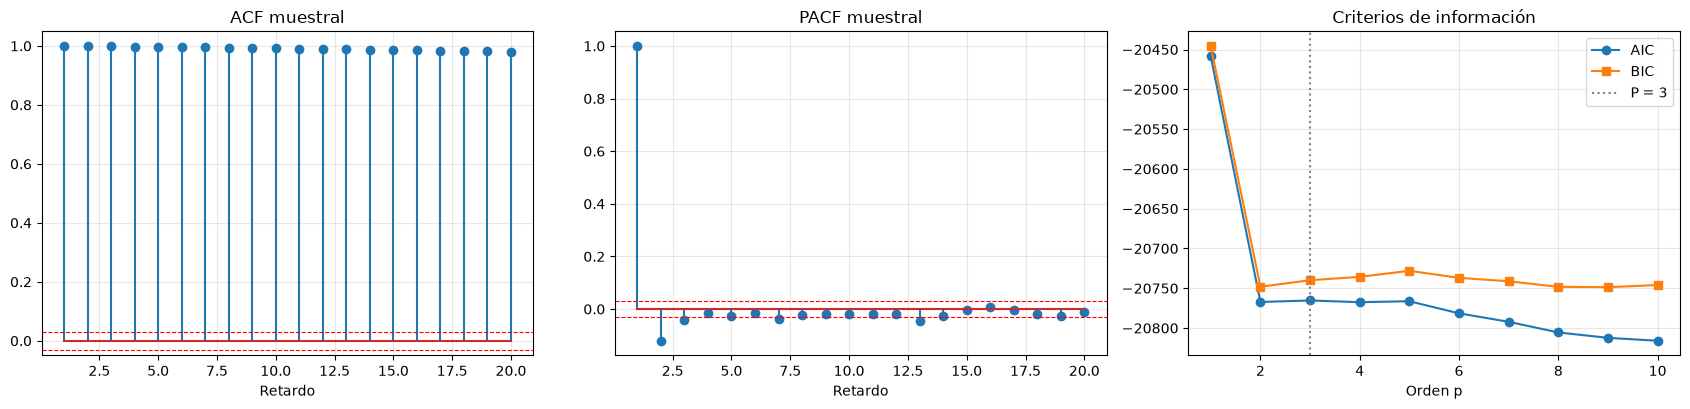

In [8]:
# ============================================================
# SELECCIÓN DEL ORDEN p DEL MODELO AR(p)
# CRITERIOS: PACF, AIC Y BIC
# ============================================================

y = Ta.to_numpy(dtype=float)
N = len(y)

if N <= 3 * P_MAX:
    raise ValueError("Serie demasiado corta para evaluar P_MAX.")

# ------------------------------------------------------------
# 1. ACF Y PACF MUESTRALES
# ------------------------------------------------------------
NLAGS = max(P_MAX, 20)
rho_k = acf(y, NLAGS)
pacf_k = pacf(y, NLAGS)
banda = 1.96 / np.sqrt(N)

# ------------------------------------------------------------
# 2. AJUSTE DE AR(1)..AR(P_MAX) SOBRE LA MISMA MUESTRA
# ------------------------------------------------------------
# Se descartan los primeros P_MAX datos para que todos los
# órdenes usen exactamente las mismas n observaciones de Y.
filas = []

for p in range(1, P_MAX + 1):

    Yp = y[P_MAX:]
    Xp = np.column_stack(
        [np.ones(N - P_MAX)] +
        [y[P_MAX - i: N - i] for i in range(1, p + 1)]
    )

    beta, *_ = np.linalg.lstsq(Xp, Yp, rcond=None)
    res_p = Yp - Xp @ beta

    n_p = len(Yp)
    sse_p = float(res_p @ res_p)
    k_p = p + 1

    aic = n_p * np.log(sse_p / n_p) + 2 * k_p
    bic = n_p * np.log(sse_p / n_p) + k_p * np.log(n_p)

    filas.append({
        "p": p,
        "RMSE": np.sqrt(sse_p / n_p),
        "AIC": aic,
        "BIC": bic,
        "Suma_phi": beta[1:].sum()
    })

criterios = pd.DataFrame(filas)

p_aic = int(criterios.loc[criterios["AIC"].idxmin(), "p"])
p_bic = int(criterios.loc[criterios["BIC"].idxmin(), "p"])

# último retardo significativo de la PACF dentro de 1..P_MAX
signif = [k for k in range(1, P_MAX + 1) if abs(pacf_k[k]) > banda]
p_pacf = max(signif) if signif else 0

# ------------------------------------------------------------
# 3. RESULTADOS
# ------------------------------------------------------------
print("=" * 55)
print("SELECCIÓN DEL ORDEN p")
print("=" * 55)
print(f"Observaciones por ajuste : {N - P_MAX}")
print(f"Banda PACF (95 %)        : ±{banda:.5f}")
print(f"Último retardo PACF signif. (<= P_MAX): {p_pacf}")
print(f"p que minimiza AIC       : {p_aic}")
print(f"p que minimiza BIC       : {p_bic}")
print(f"p configurado (P)        : {P}")

display(criterios.round(6))

# ------------------------------------------------------------
# 4. GRÁFICAS
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

lags = np.arange(1, NLAGS + 1)

ax[0].stem(lags, rho_k[1:])
ax[0].axhline(banda, color="red", linestyle="--", linewidth=0.8)
ax[0].axhline(-banda, color="red", linestyle="--", linewidth=0.8)
ax[0].set_title("ACF muestral")
ax[0].set_xlabel("Retardo")
ax[0].grid(alpha=0.3)

ax[1].stem(lags, pacf_k[1:])
ax[1].axhline(banda, color="red", linestyle="--", linewidth=0.8)
ax[1].axhline(-banda, color="red", linestyle="--", linewidth=0.8)
ax[1].set_title("PACF muestral")
ax[1].set_xlabel("Retardo")
ax[1].grid(alpha=0.3)

ax[2].plot(criterios["p"], criterios["AIC"], marker="o", label="AIC")
ax[2].plot(criterios["p"], criterios["BIC"], marker="s", label="BIC")
ax[2].axvline(P, color="gray", linestyle=":", label=f"P = {P}")
ax[2].set_title("Criterios de información")
ax[2].set_xlabel("Orden p")
ax[2].legend()
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Orden del modelo        : AR(3)
Número de observaciones originales: 4320
Número de filas (N - p)            : 4317

RESULTADOS DEL MODELO AR(3)
Número de filas   = 4317
Media Y           = 18.47146166
Media X1          = 18.47123002
Media X2          = 18.47088256
Media X3          = 18.47041927
Cond(Sxx)         = 3.204e+04
Sigma^2           = 0.00810026
RMSE              = 0.08995973
MAE               = 0.06176439
R2                = 0.99964390
AIC               = -20786.0667
BIC               = -20760.5854
RMSE persistencia = 0.09342528  (mejora del AR(3): 3.71 %)

Parámetros estimados:


,Parámetro,Estimado,Error estándar,t
0,c,0.003999,0.005483,0.729414
1,phi_1,1.266538,0.015220,83.214579
2,phi_2,-0.256824,0.024252,-10.589738
3,phi_3,-0.009923,0.015212,-0.652326



Modelo estimado:
Ta(t) = 0.00399939 + (1.26653790)*Ta(t-1) + (-0.25682399)*Ta(t-2) + (-0.00992316)*Ta(t-3)

Estacionariedad:
  Suma de phi_i      = 0.99979075
  Raíces (lambda)    = [ 0.999711  0.299923 -0.033095]
  Módulo máximo      = 0.99971069

AR(3) estimado: condición max|lambda| < 1 satisfecha.
Media del proceso mu = c/(1-sum phi) = 19.113346

Primeras filas de la tabla:


,t,Ta_t-1,Ta_t-2,Ta_t-3,Ta_t,Ta_t-1-media,Ta_t-2-media,Ta_t-3-media,Y-Ymedia,Ta_estimado,Residual,Residual^2
0,4,24.2,23.9,23.6,24.5,5.72877,5.429117,5.129581,6.028538,24.281937,0.218063,4.755159e-02
1,5,24.5,24.2,23.9,24.9,6.02877,5.729117,5.429581,6.428538,24.581874,0.318126,1.012042e-01
2,6,24.9,24.5,24.2,25.1,6.42877,6.029117,5.729581,6.628538,25.008465,0.091535,8.378662e-03
3,7,25.1,24.9,24.5,25.2,6.62877,6.429117,6.029581,6.728538,25.156066,0.043934,1.930196e-03
4,8,25.2,25.1,24.9,25.2,6.72877,6.629117,6.429581,6.728538,25.227386,-0.027386,7.499786e-04
5,9,25.2,25.2,25.1,25.2,6.72877,6.729117,6.629581,6.728538,25.199719,0.000281,7.912554e-08
6,10,25.2,25.2,25.2,25.2,6.72877,6.729117,6.729581,6.728538,25.198726,0.001274,1.622078e-06
7,11,25.2,25.2,25.2,25.3,6.72877,6.729117,6.729581,6.828538,25.198726,0.101274,1.025634e-02
8,12,25.3,25.2,25.2,25.5,6.82877,6.729117,6.729581,7.028538,25.325380,0.174620,3.049208e-02
9,13,25.5,25.3,25.2,25.6,7.02877,6.829117,6.729581,7.128538,25.553005,0.046995,2.208496e-03



Último dato observado: Ta(4320) = 25.2000
Predicción a un paso : Ta(4321) = 25.1434
Predicción a H = 30  : Ta(4350) = 25.0695


,t,h,Pronostico,Limite_inf_95,Limite_sup_95
0,4321,1,25.143392,24.966990,25.319795
1,4322,2,25.125046,24.840380,25.409712
2,4323,3,25.118333,24.747495,25.489170
3,4324,4,25.115103,24.672353,25.557853
4,4325,5,25.112919,24.607820,25.618018
5,4326,6,25.111049,24.550358,25.671741
6,4327,7,25.109274,24.498007,25.720541
7,4328,8,25.107527,24.449574,25.765480
8,4329,9,25.105789,24.404270,25.807308
9,4330,10,25.104054,24.361544,25.846565


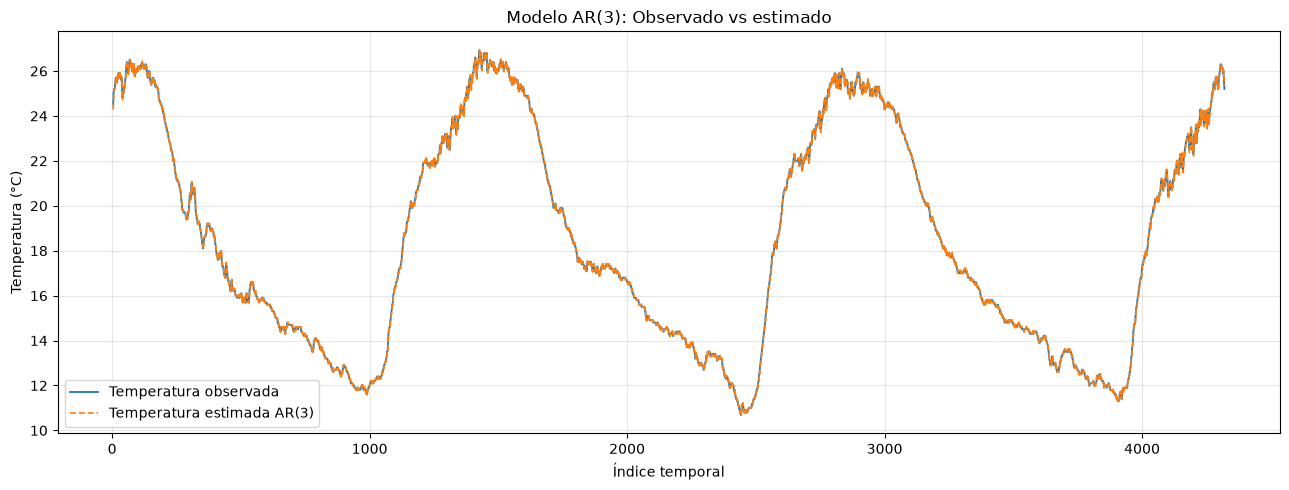

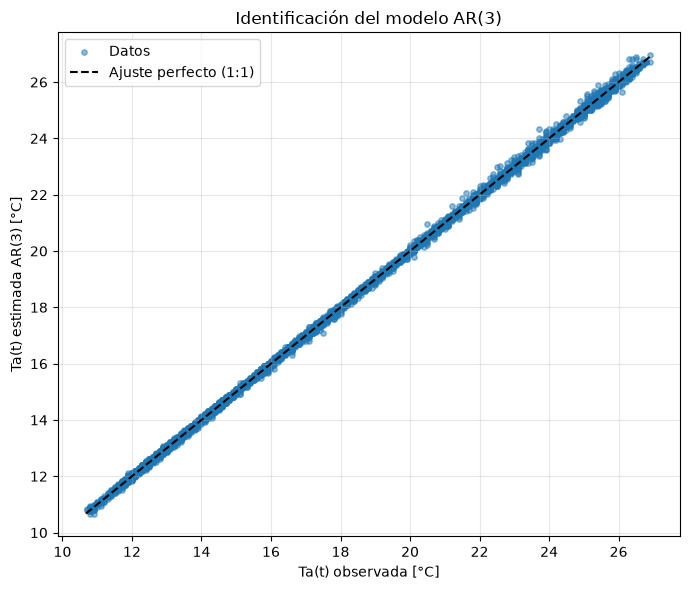

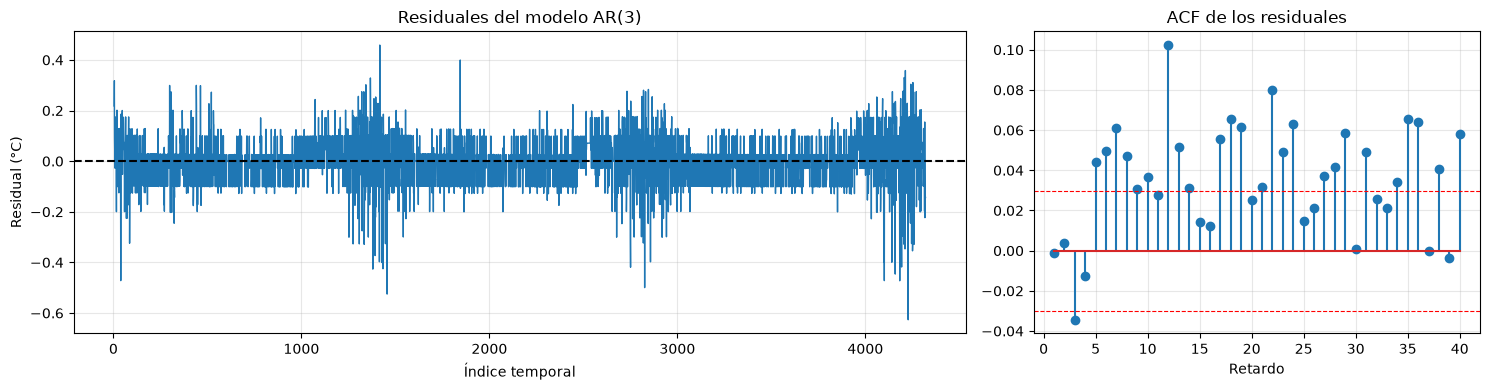

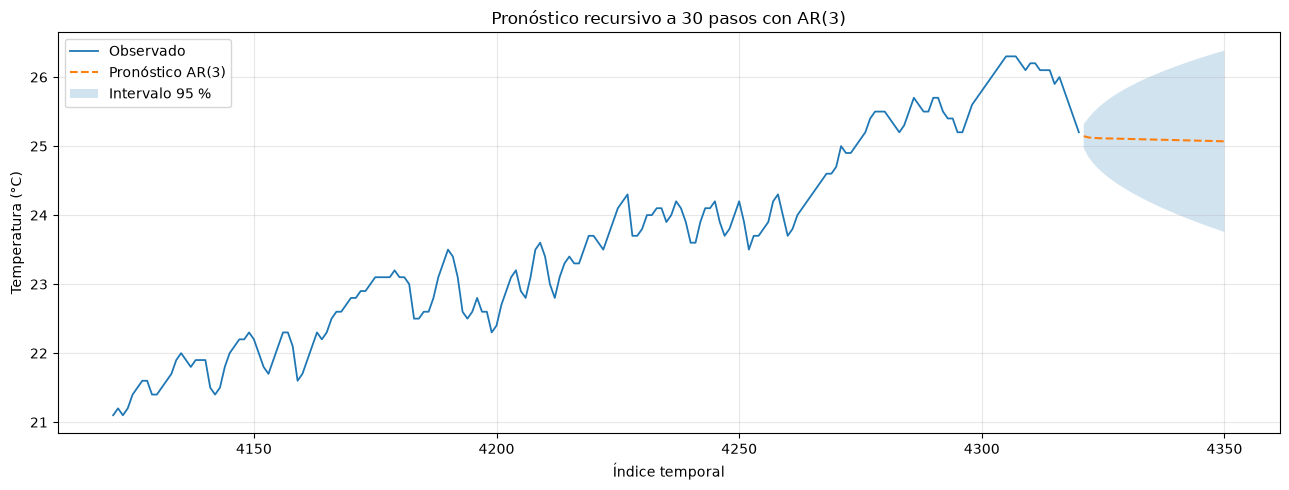


Archivo generado: Resultados_Modelo_AR3.xlsx


In [5]:
# ============================================================
# ESTIMACIÓN DEL MODELO AUTORREGRESIVO AR(p)
# MÉTODO: MÍNIMOS CUADRADOS ORDINARIOS
# VARIABLE: TEMPERATURA Ta
# ENTORNO: GOOGLE COLAB
# ============================================================

y = Ta.to_numpy(dtype=float)
N = len(y)

# ============================================================
# 1. CONSTRUIR LA MATRIZ DE REZAGOS
# ============================================================
# Y[k]    = Ta(t)
# X[k, i] = Ta(t-(i+1))     (columna i  <->  rezago i+1)

Y, X = matriz_rezagos(y, P)
n = len(Y)

if n <= P + 1:
    raise ValueError("Muy pocos datos para estimar el modelo.")

nombres_x = [f"Ta_t-{i}" for i in range(1, P + 1)]

tabla = pd.DataFrame(X, columns=nombres_x)
tabla.insert(0, "t", np.arange(P + 1, N + 1))
tabla["Ta_t"] = Y

print(f"Orden del modelo        : AR({P})")
print("Número de observaciones originales:", N)
print("Número de filas (N - p)            :", n)

# ============================================================
# 2. CÁLCULO DE LAS MEDIAS
# ============================================================

X_media = X.mean(axis=0)          # vector (p,)
Y_media = Y.mean()

# ============================================================
# 3. DESVIACIONES RESPECTO A LAS MEDIAS
# ============================================================

dX = X - X_media                  # (n, p)
dY = Y - Y_media                  # (n,)

# ============================================================
# 4. MATRIZ Sxx (p x p) Y VECTOR Sxy (p,)
# ============================================================

Sxx = dX.T @ dX
Sxy = dX.T @ dY

cond_Sxx = np.linalg.cond(Sxx)

if (not np.isfinite(cond_Sxx)) or cond_Sxx > 1e12:
    raise ValueError(
        "Sxx es singular o está muy mal condicionada "
        f"(cond = {cond_Sxx:.3e}): los rezagos son casi colineales. "
        "Reduzca P."
    )

# ============================================================
# 5. COEFICIENTES AUTORREGRESIVOS (ECUACIONES NORMALES)
# ============================================================

phi = np.linalg.solve(Sxx, Sxy)   # (p,)

# ============================================================
# 6. INTERCEPTO
# ============================================================

c = Y_media - X_media @ phi

# ============================================================
# 7. VALORES ESTIMADOS (PREDICCIÓN A UN PASO)
# ============================================================

Y_estimado = c + X @ phi

# ============================================================
# 8. RESIDUALES
# ============================================================

residuales = Y - Y_estimado

# ============================================================
# 9. MÉTRICAS DE DESEMPEÑO
# ============================================================

SSE = np.sum(residuales**2)
SST = np.sum((Y - Y_media)**2)

RMSE = np.sqrt(np.mean(residuales**2))
MAE = np.mean(np.abs(residuales))

R2 = 1 - SSE / SST if SST > 0 else np.nan

sigma2 = SSE / (n - P - 1)                      # varianza del ruido
AIC = n * np.log(SSE / n) + 2 * (P + 1)
BIC = n * np.log(SSE / n) + (P + 1) * np.log(n)

# Modelo ingenuo de persistencia: Ta(t) ~ Ta(t-1)
RMSE_pers = np.sqrt(np.mean((Y - X[:, 0])**2))
mejora_pers = 100 * (1 - RMSE / RMSE_pers)

# ============================================================
# 10. ERRORES ESTÁNDAR Y ESTADÍSTICO t
# ============================================================

Sxx_inv = np.linalg.inv(Sxx)
se_phi = np.sqrt(sigma2 * np.diag(Sxx_inv))
t_phi = phi / se_phi

se_c = np.sqrt(sigma2 * (1.0 / n + X_media @ Sxx_inv @ X_media))
t_c = c / se_c

# ============================================================
# 11. ESTACIONARIEDAD (RAÍCES DEL POLINOMIO CARACTERÍSTICO)
# ============================================================
# lambda^p - phi_1 lambda^(p-1) - ... - phi_p = 0

raices = np.roots(np.concatenate(([1.0], -phi)))
radio_max = np.max(np.abs(raices))
suma_phi = phi.sum()
estacionario = radio_max < 1

if estacionario and abs(1 - suma_phi) > 1e-12:
    mu = c / (1 - suma_phi)                     # media del proceso
else:
    mu = np.nan

# ============================================================
# 12. TABLA DE CÁLCULOS INTERMEDIOS
# ============================================================

for i, nombre in enumerate(nombres_x):
    tabla[f"{nombre}-media"] = dX[:, i]

tabla["Y-Ymedia"] = dY
tabla["Ta_estimado"] = Y_estimado
tabla["Residual"] = residuales
tabla["Residual^2"] = residuales**2

parametros = pd.DataFrame({
    "Parámetro": ["c"] + [f"phi_{i}" for i in range(1, P + 1)],
    "Estimado": np.concatenate(([c], phi)),
    "Error estándar": np.concatenate(([se_c], se_phi)),
    "t": np.concatenate(([t_c], t_phi)),
})

# ============================================================
# 13. PRESENTAR RESULTADOS
# ============================================================

print("\n" + "=" * 55)
print(f"RESULTADOS DEL MODELO AR({P})")
print("=" * 55)

print(f"Número de filas   = {n}")
print(f"Media Y           = {Y_media:.8f}")
for i in range(P):
    print(f"Media X{i + 1:<2d}         = {X_media[i]:.8f}")
print(f"Cond(Sxx)         = {cond_Sxx:.3e}")
print(f"Sigma^2           = {sigma2:.8f}")
print(f"RMSE              = {RMSE:.8f}")
print(f"MAE               = {MAE:.8f}")
print(f"R2                = {R2:.8f}")
print(f"AIC               = {AIC:.4f}")
print(f"BIC               = {BIC:.4f}")
print(f"RMSE persistencia = {RMSE_pers:.8f}  "
      f"(mejora del AR({P}): {mejora_pers:.2f} %)")

print("\nParámetros estimados:")
display(parametros)

termino = " + ".join(
    f"({phi[i]:.8f})*Ta(t-{i + 1})" for i in range(P)
)
print("\nModelo estimado:")
print(f"Ta(t) = {c:.8f} + {termino}")

print("\nEstacionariedad:")
print(f"  Suma de phi_i      = {suma_phi:.8f}")
print(f"  Raíces (lambda)    = {np.round(raices, 6)}")
print(f"  Módulo máximo      = {radio_max:.8f}")

if estacionario:
    print(f"\nAR({P}) estimado: condición max|lambda| < 1 satisfecha.")
    if np.isfinite(mu):
        print(f"Media del proceso mu = c/(1-sum phi) = {mu:.6f}")
else:
    print("\nAdvertencia: max|lambda| >= 1, el modelo no es estacionario.")

print("\nPrimeras filas de la tabla:")
display(tabla.head(10))

# ============================================================
# 14. PRONÓSTICO RECURSIVO A H PASOS
# ============================================================
# X^(t+h) = c + sum_i phi_i X^(t+h-i), con X^(t+j) = X(t+j) si j <= 0

buffer = list(y[-P:])                     # últimos P datos (el más antiguo primero)
pronostico = []

for h in range(H):
    nuevo = c + sum(phi[i - 1] * buffer[-i] for i in range(1, P + 1))
    pronostico.append(nuevo)
    buffer.append(nuevo)

pronostico = np.array(pronostico)

# Pesos psi (representación MA(inf)) para el intervalo de pronóstico
psi = np.zeros(H)
psi[0] = 1.0
for j in range(1, H):
    psi[j] = sum(phi[i - 1] * psi[j - i] for i in range(1, min(j, P) + 1))

error_h = np.sqrt(sigma2 * np.cumsum(psi**2))
li = pronostico - 1.96 * error_h
ls = pronostico + 1.96 * error_h

tabla_pron = pd.DataFrame({
    "t": np.arange(N + 1, N + H + 1),
    "h": np.arange(1, H + 1),
    "Pronostico": pronostico,
    "Limite_inf_95": li,
    "Limite_sup_95": ls,
})

print(f"\nÚltimo dato observado: Ta({N}) = {y[-1]:.4f}")
print(f"Predicción a un paso : Ta({N + 1}) = {pronostico[0]:.4f}")
print(f"Predicción a H = {H}  : Ta({N + H}) = {pronostico[-1]:.4f}")

display(tabla_pron.head(10))

# ============================================================
# 15. GRÁFICA: OBSERVADO VS ESTIMADO
# ============================================================

plt.figure(figsize=(13, 5))

plt.plot(
    tabla["t"], Y,
    label="Temperatura observada",
    linewidth=1.3
)

plt.plot(
    tabla["t"], Y_estimado,
    label=f"Temperatura estimada AR({P})",
    linewidth=1.2,
    linestyle="--"
)

plt.xlabel("Índice temporal")
plt.ylabel("Temperatura (°C)")
plt.title(f"Modelo AR({P}): Observado vs estimado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 16. GRÁFICA: ESTIMADO VS OBSERVADO (AJUSTE)
# ============================================================
# Con p > 1 ya no existe una recta en el plano (X, Y); se grafica
# la predicción contra el dato real (ideal: sobre la recta 1:1).

plt.figure(figsize=(7, 6))

plt.scatter(
    Y, Y_estimado,
    alpha=0.5,
    s=15,
    label="Datos"
)

lim = [min(Y.min(), Y_estimado.min()), max(Y.max(), Y_estimado.max())]
plt.plot(lim, lim, color="black", linestyle="--", linewidth=1.5,
         label="Ajuste perfecto (1:1)")

plt.xlabel("Ta(t) observada [°C]")
plt.ylabel(f"Ta(t) estimada AR({P}) [°C]")
plt.title(f"Identificación del modelo AR({P})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 17. GRÁFICAS DE RESIDUALES (SERIE Y ACF)
# ============================================================

NLAGS_RES = 40
acf_res = acf(residuales, NLAGS_RES)
banda_res = 1.96 / np.sqrt(n)

fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})

ax[0].plot(tabla["t"], residuales, linewidth=1)
ax[0].axhline(0, color="black", linestyle="--")
ax[0].set_xlabel("Índice temporal")
ax[0].set_ylabel("Residual (°C)")
ax[0].set_title(f"Residuales del modelo AR({P})")
ax[0].grid(alpha=0.3)

ax[1].stem(np.arange(1, NLAGS_RES + 1), acf_res[1:])
ax[1].axhline(banda_res, color="red", linestyle="--", linewidth=0.8)
ax[1].axhline(-banda_res, color="red", linestyle="--", linewidth=0.8)
ax[1].set_xlabel("Retardo")
ax[1].set_title("ACF de los residuales")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 18. GRÁFICA DEL PRONÓSTICO
# ============================================================

N_HIST = min(200, N)

plt.figure(figsize=(13, 5))

plt.plot(
    np.arange(N - N_HIST + 1, N + 1), y[-N_HIST:],
    label="Observado", linewidth=1.3
)
plt.plot(
    tabla_pron["t"], pronostico,
    label=f"Pronóstico AR({P})", linewidth=1.5, linestyle="--"
)
plt.fill_between(
    tabla_pron["t"], li, ls,
    alpha=0.2, label="Intervalo 95 %"
)

plt.xlabel("Índice temporal")
plt.ylabel("Temperatura (°C)")
plt.title(f"Pronóstico recursivo a {H} pasos con AR({P})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 19. EXPORTAR RESULTADOS A EXCEL
# ============================================================

resumen = pd.DataFrame({
    "Parámetro": [
        "Orden p", "N original", "N filas",
        "Media Y",
        "Sigma^2", "SSE", "SST",
        "RMSE", "MAE", "R2",
        "AIC", "BIC",
        "RMSE persistencia", "Mejora vs persistencia (%)",
        "Suma phi", "Módulo máximo de raíces",
        "Estacionario", "Media del proceso (mu)"
    ],
    "Valor": [
        P, N, n,
        Y_media,
        sigma2, SSE, SST,
        RMSE, MAE, R2,
        AIC, BIC,
        RMSE_pers, mejora_pers,
        suma_phi, radio_max,
        "Sí" if estacionario else "No", mu
    ]
})

archivo_salida = f"Resultados_Modelo_AR{P}.xlsx"

with pd.ExcelWriter(
    archivo_salida,
    engine="openpyxl"
) as writer:

    pd.DataFrame({"t": np.arange(1, N + 1), "Ta": y}).to_excel(
        writer,
        sheet_name="Serie Original",
        index=False
    )

    tabla.to_excel(
        writer,
        sheet_name=f"Calculos AR{P}",
        index=False
    )

    parametros.to_excel(
        writer,
        sheet_name="Parametros",
        index=False
    )

    resumen.to_excel(
        writer,
        sheet_name="Resultados",
        index=False
    )

    tabla_pron.to_excel(
        writer,
        sheet_name="Pronostico",
        index=False
    )

print("\nArchivo generado:", archivo_salida)
#files.download(archivo_salida)